## Постановка цели, описание исходных данных.

Есть интернет-магазин , который продаёт по всему миру компьютерные игры. 

**Дано:** исторические данные о продажах игр, оценки пользователей и экспертов, жанры и платформы (например, Xbox или PlayStation). 
данные до 2016 года, планируется рекламная компания на 2017.

**Цель:** выявить определяющие успешность игры закономерности. для того, чтобы сделать ставку на потенциально популярный продукт и спланировать рекламные кампании.

**Описание данных:**
- Name — название игры
- Platform — платформа
- Year_of_Release — год выпуска
- Genre — жанр игры
- NA_sales — продажи в Северной Америке (миллионы проданных копий)
- EU_sales — продажи в Европе (миллионы проданных копий)
- JP_sales — продажи в Японии (миллионы проданных копий)
- Other_sales — продажи в других странах (миллионы проданных копий)
- Critic_Score — оценка критиков (максимум 100)
- User_Score — оценка пользователей (максимум 10)
- Rating — рейтинг от организации ESRB (англ. Entertainment Software Rating Board). Эта ассоциация определяет рейтинг компьютерных игр и присваивает им подходящую возрастную категорию.

## Откройте файл с данными и изучите общую информацию

In [2]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats as st
import pylab as pl
from pandas import *   # означает, что импортируются все функции и модули библиотеки Pandas

In [3]:
df = pd.read_csv('/datasets/games.csv')

In [4]:
df.head(5)

,Name,Platform,Year_of_Release,Genre,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score,User_Score,Rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


In [5]:
display(df.info())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Name             16713 non-null  object 
 1   Platform         16715 non-null  object 
 2   Year_of_Release  16446 non-null  float64
 3   Genre            16713 non-null  object 
 4   NA_sales         16715 non-null  float64
 5   EU_sales         16715 non-null  float64
 6   JP_sales         16715 non-null  float64
 7   Other_sales      16715 non-null  float64
 8   Critic_Score     8137 non-null   float64
 9   User_Score       10014 non-null  object 
 10  Rating           9949 non-null   object 
dtypes: float64(6), object(5)
memory usage: 1.4+ MB


None

,Year_of_Release,NA_sales,EU_sales,JP_sales,Other_sales,Critic_Score
count,16446.000000,16715.000000,16715.000000,16715.000000,16715.000000,8137.000000
mean,2006.484616,0.263377,0.145060,0.077617,0.047342,68.967679
std,5.877050,0.813604,0.503339,0.308853,0.186731,13.938165
min,1980.000000,0.000000,0.000000,0.000000,0.000000,13.000000
25%,2003.000000,0.000000,0.000000,0.000000,0.000000,60.000000
50%,2007.000000,0.080000,0.020000,0.000000,0.010000,71.000000
75%,2010.000000,0.240000,0.110000,0.040000,0.030000,79.000000
max,2016.000000,41.360000,28.960000,10.220000,10.570000,98.000000


In [6]:
df.isna().mean()*100

Name                0.011965
Platform            0.000000
Year_of_Release     1.609333
Genre               0.011965
NA_sales            0.000000
EU_sales            0.000000
JP_sales            0.000000
Other_sales         0.000000
Critic_Score       51.319174
User_Score         40.089740
Rating             40.478612
dtype: float64

Видим пропуски в половине строк датафрейма, столбцы информативные и важны в нашем исследовании. Поэтому скорее всего придётся , что можно - заполнить пропусками, либо рассматривать ограниченную выборку за какой-то конкретный период. Скорее всего так и буду делать.

## Подготовка данных

### Замените названия столбцов (приведите к нижнему регистру);

In [7]:
df.columns

Index(['Name', 'Platform', 'Year_of_Release', 'Genre', 'NA_sales', 'EU_sales',
       'JP_sales', 'Other_sales', 'Critic_Score', 'User_Score', 'Rating'],
      dtype='object')

In [ ]:
# переименование столбцов

df.columns = df.columns.str.lower()

In [9]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006.0,Sports,41.36,28.96,3.77,8.45,76.0,8,E
1,Super Mario Bros.,NES,1985.0,Platform,29.08,3.58,6.81,0.77,NaN,NaN,NaN
2,Mario Kart Wii,Wii,2008.0,Racing,15.68,12.76,3.79,3.29,82.0,8.3,E
3,Wii Sports Resort,Wii,2009.0,Sports,15.61,10.93,3.28,2.95,80.0,8,E
4,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,11.27,8.89,10.22,1.00,NaN,NaN,NaN


### Преобразуйте данные в нужные типы. Опишите, в каких столбцах заменили тип данных и почему;

из метода info применённого выше видим, что 'name', 'platform', 'genre', 'rating' - относятся к типу данных object и у них тип задан верно менять не будем.

'NA_sales', 'EU_sales','JP_sales', 'Other_sales' - относятся к типу float, тут тоже всё в порядке.

*year_of_release - заменим тип float64 на тип int*

*critic_score - заменим тип float64 на int,*

*user_score - заменим тип object на float64.*

In [10]:
df['year_of_release'] = df['year_of_release'].astype('Int64')

In [11]:
df['critic_score'] = df['critic_score'].astype('Int64')

In [12]:
# воспользоваться numeric сразу не получилось так как мешали значения "tbd", заменю их NaN
df['user_score'] = df['user_score'].replace('tbd',np.NaN)
df['user_score'] = pd.to_numeric(df['user_score'])

# или можно так 

#df['user_score'] = pd.to_numeric(df['user_score'], errors='coerce')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  Int64  
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   Int64  
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
dtypes: Int64(2), float64(5), object(4)
memory usage: 1.4+ MB


In [14]:
df.head(5)

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,<NA>,NaN,NaN
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,<NA>,NaN,NaN


### Обработайте пропуски при необходимости:

In [15]:
df.isna().mean()*100

name                0.011965
platform            0.000000
year_of_release     1.609333
genre               0.011965
na_sales            0.000000
eu_sales            0.000000
jp_sales            0.000000
other_sales         0.000000
critic_score       51.319174
user_score         54.591684
rating             40.478612
dtype: float64

Обработаю пропуски в столбце 'year_of_release', заменив их наиболее часто встречаемыми значениями в группе.

пропуски в названиях заменю на 'unnamed'

In [18]:
df['name'] = df['name'].fillna('unnamed')

In [19]:
df[df['name'] == 'unnamed']

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating
659,unnamed,GEN,1993,NaN,1.78,0.53,0.00,0.08,<NA>,NaN,NaN
14244,unnamed,GEN,1993,NaN,0.00,0.00,0.03,0.00,<NA>,NaN,NaN


посмотрим какие жанры чаще всего выпускала эта платформа и заменим 2 пропуска на соответствующий жанр.

In [20]:
df[df['platform'] == 'GEN']['genre'].value_counts()

genre
Platform        7
Fighting        5
Action          3
Sports          3
Role-Playing    3
Adventure       2
Strategy        1
Racing          1
Shooter         1
Misc            1
Name: count, dtype: int64

In [21]:
df['genre'] = df['genre'].fillna('Platform')

In [22]:
df.isna().mean()*100

name                0.000000
platform            0.000000
year_of_release     1.609333
genre               0.000000
na_sales            0.000000
eu_sales            0.000000
jp_sales            0.000000
other_sales         0.000000
critic_score       51.319174
user_score         54.591684
rating             40.478612
dtype: float64

1. решил не заполнять пропуски в critic_score, user_score потому, что определить эти значения по каким-то косвенным факторам мне не представляется возможным, а заменять их на средние значения не правильно, так как их очень много (больше 50 процентов) и заменив их мы исказим картину с рейтингом.
2. сейчас понял почему лучше заменить пропуски в raiting, но сразу это было непонятно, нужно чтобы игры без возрастного рейтинга отображались в портретах пользователей.
итак заменю их значением "undefined".

In [23]:
df['rating'] = df['rating'].fillna('undefined')
df.isna().mean()*100

name                0.000000
platform            0.000000
year_of_release     1.609333
genre               0.000000
na_sales            0.000000
eu_sales            0.000000
jp_sales            0.000000
other_sales         0.000000
critic_score       51.319174
user_score         54.591684
rating              0.000000
dtype: float64

### Пояснение, почему заполнил пропуски определённым образом;

Пропуски заполнил в столбцах - название , жанр (по 2 пропуска). Пропуски в столбце жанр заполнял по наиболее часто встречающемуся в категории. Пропуски в назвниях заменил на 'unnamed'. Ещё я заполнил пропуски в столбце 'rating' (заменил на indefined). 

### Возможные причины, которые могли привести к пропускам;

как сказано в условии , данные собирали из различных открытых источников, у каждого источника своё наполнение, тип хранения, формат и т.д. 
поэтому пропуски неизбежны, в каком-то источнике чего-то может не быть или называться по другому или быть в нечитабельном формате.

Кроме того данные предоставлены за достататочно длительный период с 1980 по 2016 г., соответственно данные каких-то столбцов могут отсутствовать, не сохраниться и т.д., это ещё одна причина пропусков. 

### Пояснение про 'tbd' в столбце с оценкой пользователей. Отдельно разберу это значение и опишу, как его обработал;

 значение tbd проставлено у тех игр(товаров), где количество отзывов критиков в их базе меньше 4. Следовательно, если есть tbd, то значимость отзывов недостаточная для оценки и правильно будет заменить их на NaN.

### Посчитайте суммарные продажи во всех регионах и запишите их в отдельный столбец.

In [24]:
df['total_sales'] = df['na_sales'] + df['eu_sales'] + df['jp_sales'] + df['other_sales']

In [25]:
df.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
0,Wii Sports,Wii,2006,Sports,41.36,28.96,3.77,8.45,76,8.0,E,82.54
1,Super Mario Bros.,NES,1985,Platform,29.08,3.58,6.81,0.77,<NA>,NaN,undefined,40.24
2,Mario Kart Wii,Wii,2008,Racing,15.68,12.76,3.79,3.29,82,8.3,E,35.52
3,Wii Sports Resort,Wii,2009,Sports,15.61,10.93,3.28,2.95,80,8.0,E,32.77
4,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,11.27,8.89,10.22,1.00,<NA>,NaN,undefined,31.38


## Исследовательский анализ данных

### Посмотрите, сколько игр выпускалось в разные годы. Важны ли данные за все периоды?

In [26]:
df.groupby('year_of_release')['name'].count()

year_of_release
1980       9
1981      46
1982      36
1983      17
1984      14
1985      14
1986      21
1987      16
1988      15
1989      17
1990      16
1991      41
1992      43
1993      62
1994     121
1995     219
1996     263
1997     289
1998     379
1999     338
2000     350
2001     482
2002     829
2003     775
2004     762
2005     939
2006    1006
2007    1197
2008    1427
2009    1426
2010    1255
2011    1136
2012     653
2013     544
2014     581
2015     606
2016     502
Name: name, dtype: int64

видим, что например с 1980 по 2000 год у нас в выборке количество игр от 9 до 351, сравнительно мало. Но я пока не знаю наполненности выборок всех периодов, может основная доля пропусков по столбцам приходится именно на них, проверю это.

Для начала условно поделю столбец дата на периоды: до 2000 года, с 2001 до 2011, с 2012 до 2016 и рассмотрю их наполненность.


In [27]:
df.query('year_of_release <= 2000').isna().mean()*100

name                0.00000
platform            0.00000
year_of_release     0.00000
genre               0.00000
na_sales            0.00000
eu_sales            0.00000
jp_sales            0.00000
other_sales         0.00000
critic_score       89.72485
user_score         91.44454
rating              0.00000
total_sales         0.00000
dtype: float64

In [28]:
df.query('2001 <= year_of_release <= 2011').isna().mean()*100

name                0.000000
platform            0.000000
year_of_release     0.000000
genre               0.000000
na_sales            0.000000
eu_sales            0.000000
jp_sales            0.000000
other_sales         0.000000
critic_score       42.745238
user_score         48.967420
rating              0.000000
total_sales         0.000000
dtype: float64

In [29]:
df.query('2012 <= year_of_release <= 2016').isna().mean()*100

name                0.000000
platform            0.000000
year_of_release     0.000000
genre               0.000000
na_sales            0.000000
eu_sales            0.000000
jp_sales            0.000000
other_sales         0.000000
critic_score       54.539155
user_score         46.950797
rating              0.000000
total_sales         0.000000
dtype: float64

Исходя из наполненности выборок можно сделать вывод - рассматривать выборку первого периода не имеет смысла, там пропуски по столбцам critic_score, user_score, rating составляют около 90 %.

Для нас будут важны данные только за последний период, например за последние три года.

### Посмотрите, как менялись продажи по платформам. Выберите платформы с наибольшими суммарными продажами и постройте распределение по годам. За какой характерный срок появляются новые и исчезают старые платформы?

посмотрим на суммарные продажи по разным платформам за все годы.

In [30]:
df_1 = (
    df.groupby('platform', as_index=False)
      .agg(
          games_count=('total_sales', 'count'),
          total_sales_sum=('total_sales', 'sum')
      )
)
df_1['total_sales_sum'] = df_1['total_sales_sum'].round(2)
df_1 = df_1.sort_values('total_sales_sum', ascending=False)
df_1

,platform,games_count,total_sales_sum
16,PS2,2161,1255.77
28,X360,1262,971.42
17,PS3,1331,939.65
26,Wii,1320,907.51
4,DS,2151,806.12
15,PS,1197,730.86
6,GBA,822,317.85
18,PS4,392,314.14
19,PSP,1209,294.05
13,PC,974,259.52


<Axes: title={'center': 'суммарные продажи по разным платформам за все годы.'}, xlabel='platform'>

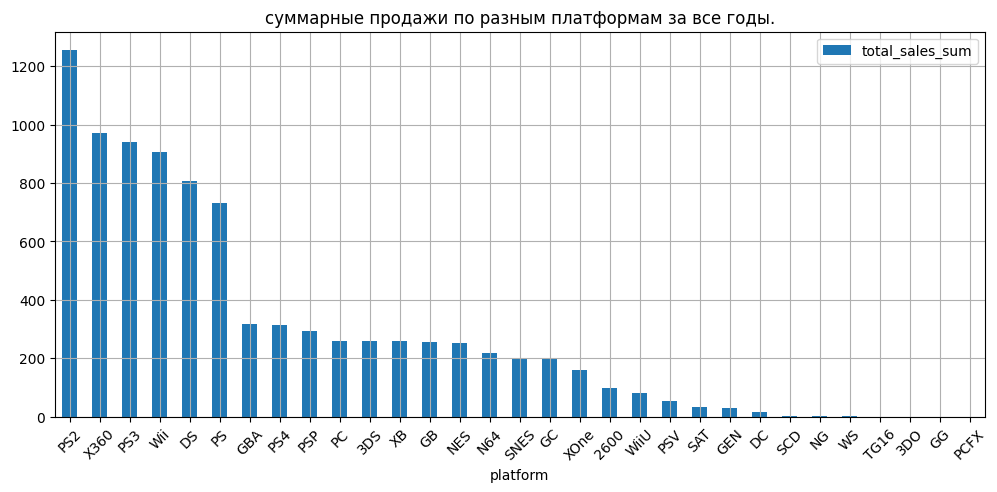

In [31]:
df_1.plot.bar(
              x='platform', 
              y = 'total_sales_sum', 
              label='total_sales_sum', 
              figsize=(12, 5),rot = 45,
              grid=True,
              title='суммарные продажи по разным платформам за все годы.'
             )

Явно выделяются платформы ТОП-6 с наибольшим отрывом в объёме продаж среди остальных: PS2, X360, PS3, Wii, DS, PS.

посмотрим на суммарные продажи по разным платформам по годам.

In [32]:
df_2 = (
    df.groupby(['platform', 'year_of_release'], as_index=False)
      .agg(
          games_count=('total_sales', 'count'),
          total_sales_sum=('total_sales', 'sum')
      )
)

# Создаём объединённый ключ
df_2['platform_year'] = df_2['platform'] + '_' + df_2['year_of_release'].astype(str)
df_2.head()

,platform,year_of_release,games_count,total_sales_sum,platform_year
0,2600,1980,9,11.38,2600_1980
1,2600,1981,46,35.68,2600_1981
2,2600,1982,36,28.88,2600_1982
3,2600,1983,11,5.84,2600_1983
4,2600,1984,1,0.27,2600_1984


Построю бар-графики суммарных продаж по годам ТОП-6 платформ, с сортировкой лет по возрастанию внутри каждой платформы (чтобы видеть исторических ход событий).

<Axes: title={'center': 'Cуммарные продажи по годам ТОП-6 платформ.'}, xlabel='platform_year'>

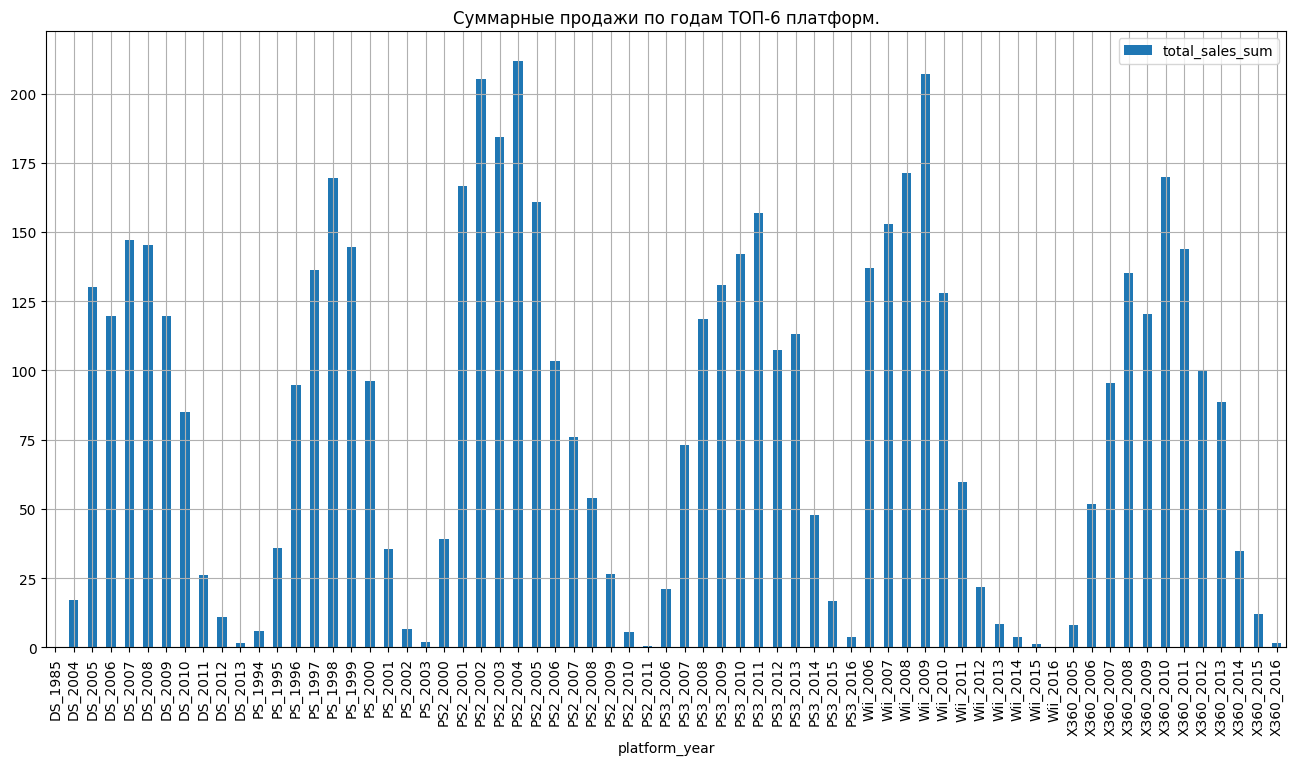

In [33]:
platforms = ['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS']
#df_3 = df_2[df_2['platform'].isin(platforms)]
df_3 = df_2.query("platform in @platforms")
df_3.plot(
    y='total_sales_sum', 
    x= 'platform_year', 
    kind = 'bar', 
    figsize=(16, 8),
    grid=True,
    #rot = 45,
    title='Cуммарные продажи по годам ТОП-6 платформ.' 
)

На графике отлично видно историческое развитие и угасание различных платформ, данные разделены по годам, годы в каждой категории отсортированы по возрастанию. Подсчитаем сколько лет занимает в среднем исторический путь каждой из выбранных платформ. График позволяет не только отследить исторический путь платформ , но и сравнить их между собой, по объёмам продаж, по динамике и длительности развития.   

In [34]:
df_3.groupby('platform')['year_of_release'].count().mean()

11.166666666666666

Исторический путь развития платформы в среднем занимает 11 лет.

In [35]:
df_3.head()

,platform,year_of_release,games_count,total_sales_sum,platform_year
25,DS,1985,1,0.02,DS_1985
26,DS,2004,23,17.27,DS_2004
27,DS,2005,118,130.14,DS_2005
28,DS,2006,201,119.81,DS_2006
29,DS,2007,376,146.94,DS_2007


отвечаю на вопрос в задании : За какой характерный срок появляются новые и исчезают старые платформы?
- 3-4 года примерно

### Возьмите данные за соответствующий актуальный период. Актуальный период определите самостоятельно в результате исследования предыдущих вопросов. Основной фактор — эти данные помогут построить прогноз на 2017 год. Не учитывайте в работе данные за предыдущие годы.

Возьму данные за 3 года, именно за такой срок появляются новые и исчезают старые платформы.

In [36]:
df_4 = df.query('year_of_release >= 2014')
df_4.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,<NA>,NaN,undefined,14.63
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97,8.3,M,12.62
47,Pokemon Omega Ruby/Pokemon Alpha Sapphire,3DS,2014,Role-Playing,4.35,3.49,3.10,0.74,<NA>,NaN,undefined,11.68
77,FIFA 16,PS4,2015,Sports,1.12,6.12,0.06,1.28,82,4.3,E,8.58
87,Star Wars Battlefront (2015),PS4,2015,Shooter,2.99,3.49,0.22,1.28,<NA>,NaN,undefined,7.98


### Какие платформы лидируют по продажам, растут или падают? Выберите несколько потенциально прибыльных платформ.
Постройте график «ящик с усами» по глобальным продажам игр в разбивке по платформам. Опишите результат.

In [37]:
df_5 = (
        df_4.groupby(['platform', 'year_of_release'], as_index=False)
        .agg(games_count=('total_sales','count'),
             total_sales_sum=('total_sales','sum'))
)

df_5['platform_year'] = df_5['platform'] + '_' + df_5['year_of_release'].astype(str)
df_5.head()

,platform,year_of_release,games_count,total_sales_sum,platform_year
0,3DS,2014,80,43.76,3DS_2014
1,3DS,2015,86,27.78,3DS_2015
2,3DS,2016,46,15.14,3DS_2016
3,PC,2014,47,13.28,PC_2014
4,PC,2015,50,8.52,PC_2015


<Axes: title={'center': 'Cуммарные продажи по годам и платформам за 2014 - 2016 г.'}, xlabel='platform_year'>

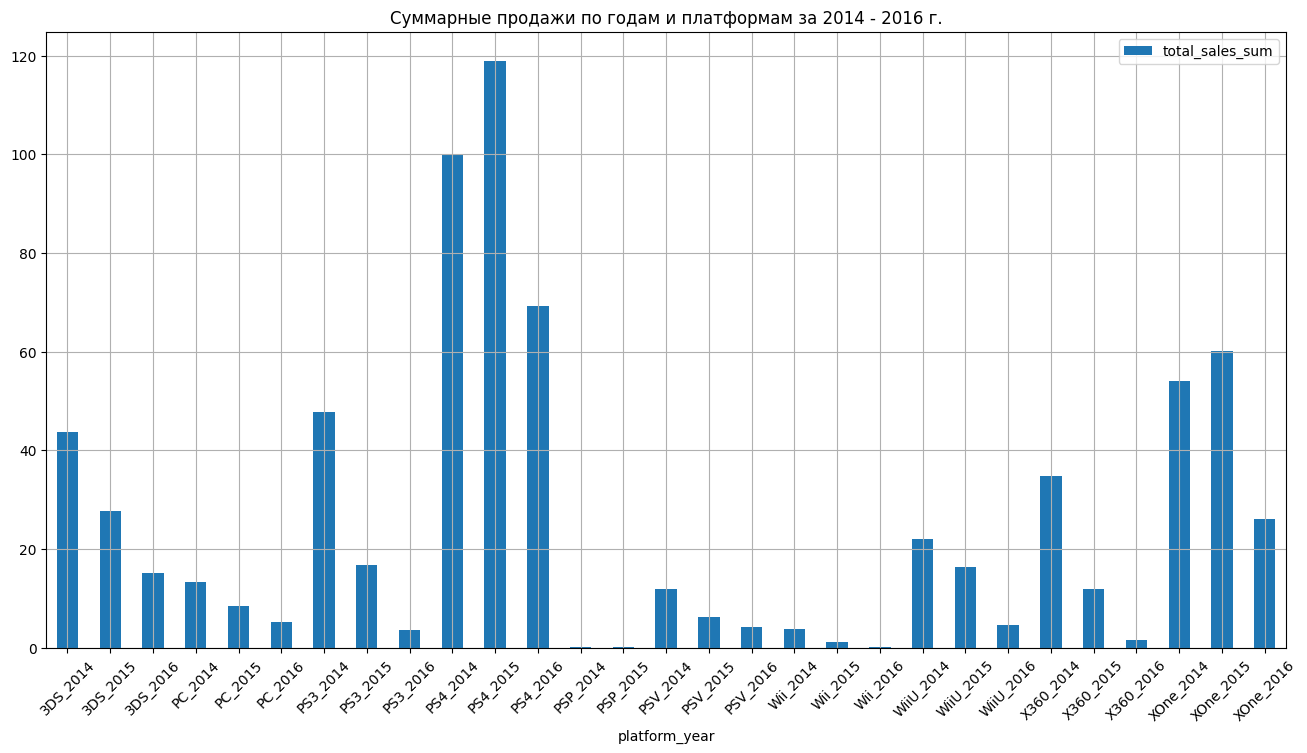

In [38]:
df_5.plot(
    y='total_sales_sum', 
    x= 'platform_year', 
    kind = 'bar', 
    figsize=(16, 8),
    grid=True,
    rot = 45,
    title='Cуммарные продажи по годам и платформам за 2014 - 2016 г.' 
)

Итак из графика видим, по что по всем платформам (представленных на графике) у нас уменьшаются объёмы продаж в течении заданного промежутка (2014 - 2016 г.). 

Из предъидущего графика мы помним, что исторический путь платформ: Wii, X360, PS3 - завершён, им на замену пришли платформы WiiU, XOne, PS4 соответственно. 

PSP - тоже отбросим, так как показатели очень низки и за 2016 год данных нет вообще, предполагаем , что платформа прекратила своё существование.

Остаётся подробнее рассмотреть следующие платформы: 3DS, PC, PSV, WiiU, XOne, PS4.
сделаем по ним выборку и построим график.

In [39]:
df_6 = df.query("platform in ['3DS', 'PC', 'PSV', 'WiiU', 'XOne', 'PS4']")
df_7 = (
        df_6
            .groupby(['platform', 'year_of_release'], as_index=False)
            .agg(games_count=('total_sales', 'count'),
                total_sales_sum=('total_sales', 'sum'))
            .assign(total_sales_sum=lambda x: x['total_sales_sum'].round(2))
)
df_7['platform_year'] = df_7['platform'] + '_' + df_7['year_of_release'].astype(str)
df_7.head()

,platform,year_of_release,games_count,total_sales_sum,platform_year
0,3DS,2011,116,63.20,3DS_2011
1,3DS,2012,93,51.36,3DS_2012
2,3DS,2013,91,56.57,3DS_2013
3,3DS,2014,80,43.76,3DS_2014
4,3DS,2015,86,27.78,3DS_2015


In [40]:
(
    df_6.query('2010<year_of_release<2016')
    .pivot_table(index='year_of_release',columns='platform',values='total_sales',aggfunc='sum')
    
)

platform,3DS,PC,PS4,PSV,WiiU,XOne
year_of_release,,,,,,
2011,63.20,35.03,NaN,4.63,NaN,NaN
2012,51.36,23.22,NaN,16.19,17.56,NaN
2013,56.57,12.38,25.99,10.59,21.65,18.96
2014,43.76,13.28,100.00,11.90,22.03,54.07
2015,27.78,8.52,118.90,6.25,16.35,60.14


<Axes: xlabel='year_of_release'>

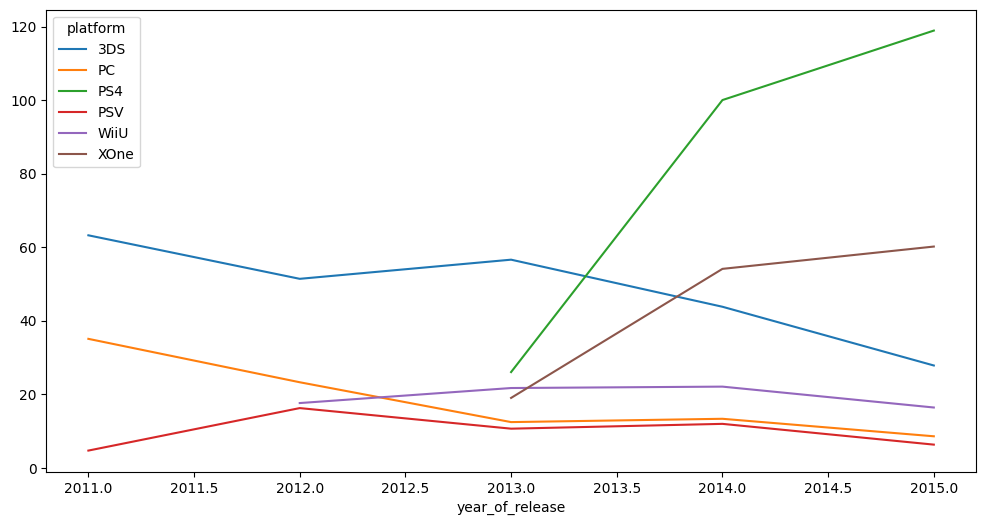

In [41]:
(
    df_6.query('2010<year_of_release<2016')
    .pivot_table(index='year_of_release',columns='platform',values='total_sales',aggfunc='sum')
    .plot(figsize=(12, 6))
)

тут также отлично видно, что все снижаются , а XOne и PS4 растут. Взял такой интервал, так как данные по отобранным платформам (кроме PC) есть начиная 2011 года, а 2016 год обрезал - так как данные по нему не полные, пояснял ниже почему.

df_7.plot(
        
    y='total_sales_sum', 
    x= 'platform_year', 
    kind = 'bar', 
    figsize=(16, 8),
    grid=True,
    #rot = 45,
    title='Cуммарные продажи по годам по платформам 3DS, PC, PSV, WiiU, XOne, PS4' 
)

**примечание:** *я думаю, что рассматривать и ориентироваться на 2016 год следует осторожно, так как данные за этот год, я полагаю, не полные. Так как, из условия, нам нужно сделать прогноз на 2017 год (тоесть он как бы ещё не настал) -> данные формировали для анализа в 2016 или в середине или в конце -> за 2016 год данные неполны и судить о суммарном объёме продаж за этот год (как за полный период) нельзя.*

Из графика видим, что на 2016 г., время существования (исторический путь) следующих платформ составляет:

In [42]:
df_7.groupby('platform')['platform_year'].count() # считаем время существования по каждой из платформ

platform
3DS      6
PC      26
PS4      4
PSV      6
WiiU     5
XOne     4
Name: platform_year, dtype: int64

Видим, что платформы XOne, PS4 находятся на этапе "роста" и скорее всего не достигли ещё середины своего пути развития.

Платформы 3DS, PSV, WiiU находятся на этапе "затухания". 

Так как в среднем, как мы подсчитали ранее, цикл жизни платформы 11 лет, то на 2017 год платформы: 3DS, PSV, WiiU, XOne, PS4 будут ещё актуальны. Лидируют по объёмам продаж - XOne, PS4.

Платформа PC - универсальная и есть почти у каждого, поэтому производство игр под неё и соответственно их продажи будет всегда актуально.

Соответственно при планировании экономической политики нашего интернет магазина "Стримчик" на 2017 год, следует сделать упор на следующие платформы: 3DS, PSV, WiiU, XOne, PS4, PC.

### Постройте график «ящик с усами» по глобальным продажам игр в разбивке по платформам. Опишите результат.

помним , что в задании сказано - не учитывайте данные за предьидущие годы.

In [43]:
df_4.head()

,name,platform,year_of_release,genre,na_sales,eu_sales,jp_sales,other_sales,critic_score,user_score,rating,total_sales
31,Call of Duty: Black Ops 3,PS4,2015,Shooter,6.03,5.86,0.36,2.38,<NA>,NaN,undefined,14.63
42,Grand Theft Auto V,PS4,2014,Action,3.96,6.31,0.38,1.97,97,8.3,M,12.62
47,Pokemon Omega Ruby/Pokemon Alpha Sapphire,3DS,2014,Role-Playing,4.35,3.49,3.10,0.74,<NA>,NaN,undefined,11.68
77,FIFA 16,PS4,2015,Sports,1.12,6.12,0.06,1.28,82,4.3,E,8.58
87,Star Wars Battlefront (2015),PS4,2015,Shooter,2.99,3.49,0.22,1.28,<NA>,NaN,undefined,7.98


<Axes: title={'center': 'total_sales'}, xlabel='platform'>

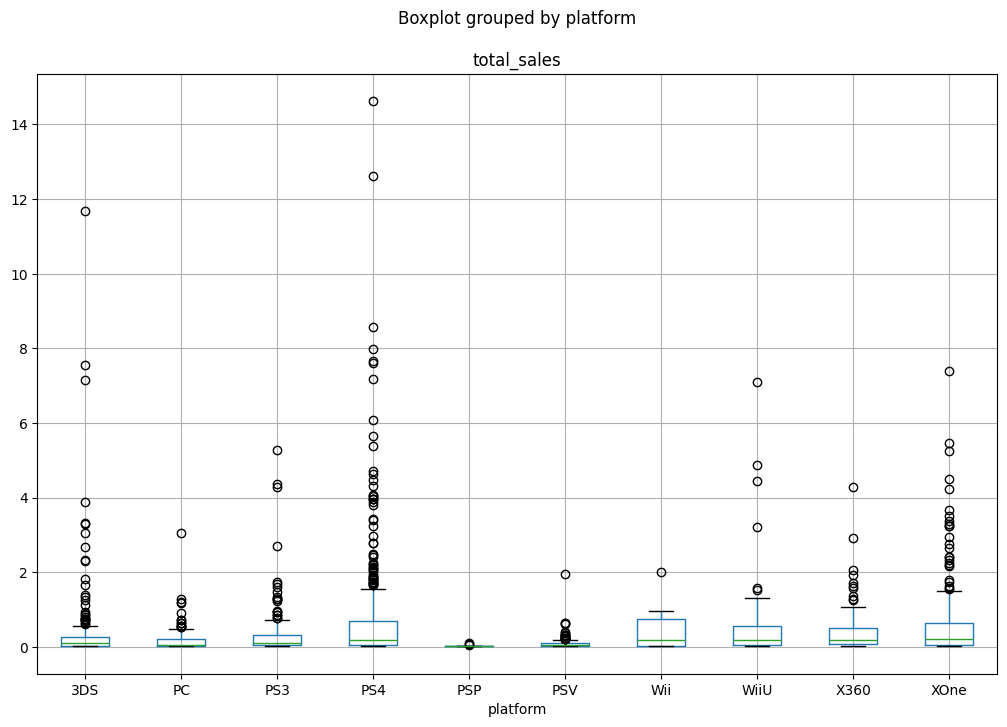

In [44]:
df_4.boxplot('total_sales', by='platform', figsize=(12,8))

диаграмма размаха показывает разброс значений в правую или левую сторону. в размах усов попадают "нормальные значения", а за пределами - "выбросы".
Вижу, что есть выбросы, в нашем случае они важны, так как можно спрогнозировать от каких платформ стоит ждать больше всего суперхитов. Видим, что таковыми являются: 3DS, PS4, XOne.

(0.0, 1.5)

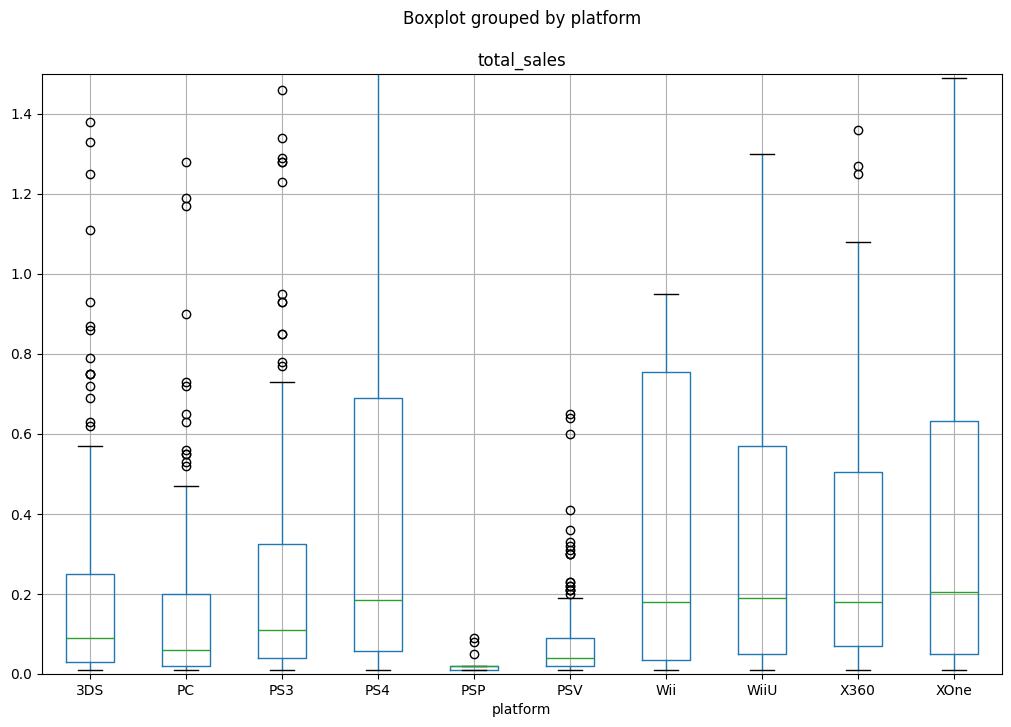

In [45]:
df_4.boxplot('total_sales', by='platform', figsize=(12,8))
plt.ylim(0, 1.5)

на данном графике я показал "нормальные значения".
Видим , что все середины распределений продаж по платформам смещены влево, засчет выбросов.

Медианы объемов продаж примерно равны по платформам PS4, WiiU, XOne и по медианным значениям они являются лидерами среди остальных платформ.

### Посмотрите, как влияют на продажи внутри одной популярной платформы отзывы пользователей и критиков. Постройте диаграмму рассеяния и посчитайте корреляцию между отзывами и продажами. Сформулируйте выводы.

Для этой цели возьмём платформу PS4.

In [46]:
df_9 = df.query("platform == 'PS4'")
len(df_9)
# (df['critic_score'] >= 70) & 

392

Сначала рассмотрим как влияют отзывы критиков на суммарные продажи.

In [47]:
df_9[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.000000,0.557654,0.406568
user_score,0.557654,1.000000,-0.031957
total_sales,0.406568,-0.031957,1.000000


Видим положительную корреляцию больше 40 % - между отзывами критиков и продажами, это значит что чем выше оценки критиков , тем выше продажи. 

И видим почти отсутствие корреляции между отзывами пользователей и продажами, но не буду спешить с выводами,

а посмотрю как эти рассеяния выглядят на графике.

<Axes: title={'center': 'диаграмма рассеяния (корреляция между отзывами критиков и продажами)'}, xlabel='critic_score', ylabel='total_sales'>

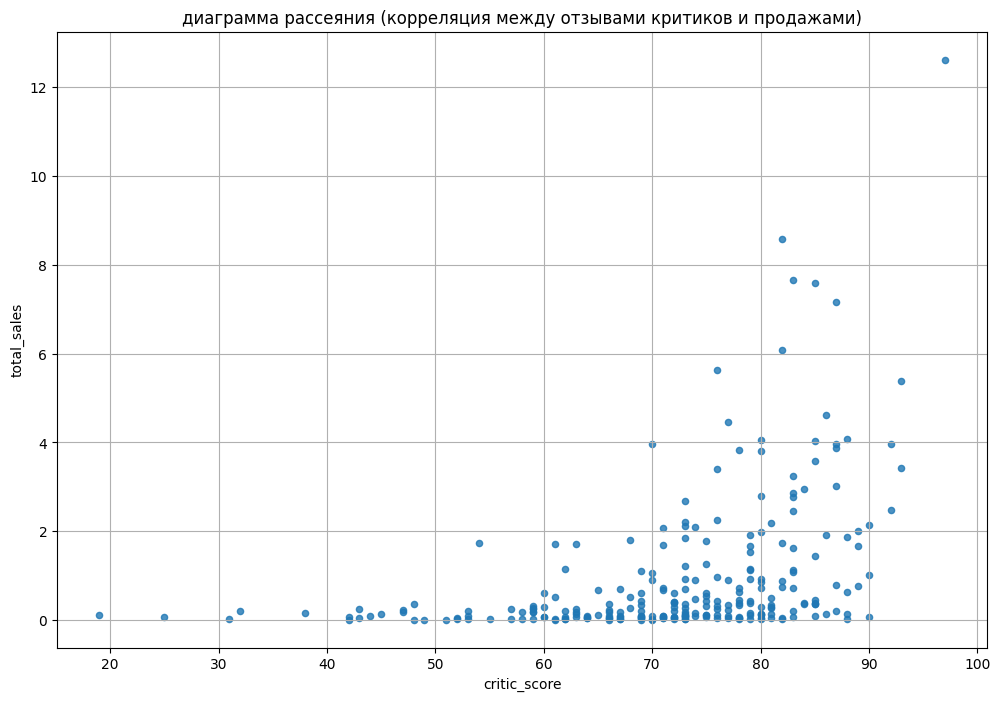

In [48]:
df_9.plot(
    x='critic_score',    
    y='total_sales', 
    kind='scatter', 
    alpha=0.8, 
   # xlim=(0, 100),
 #   ylim=(0, 6),
    figsize=(12, 8),
    grid=True,
    title='диаграмма рассеяния (корреляция между отзывами критиков и продажами)'
)

Теперь посмотрим какое влияние оказывают отзывы пользователей на суммарные продажи.

<Axes: title={'center': 'диаграмма рассеяния (корреляция между отзывами пользователей и продажами)'}, xlabel='user_score', ylabel='total_sales'>

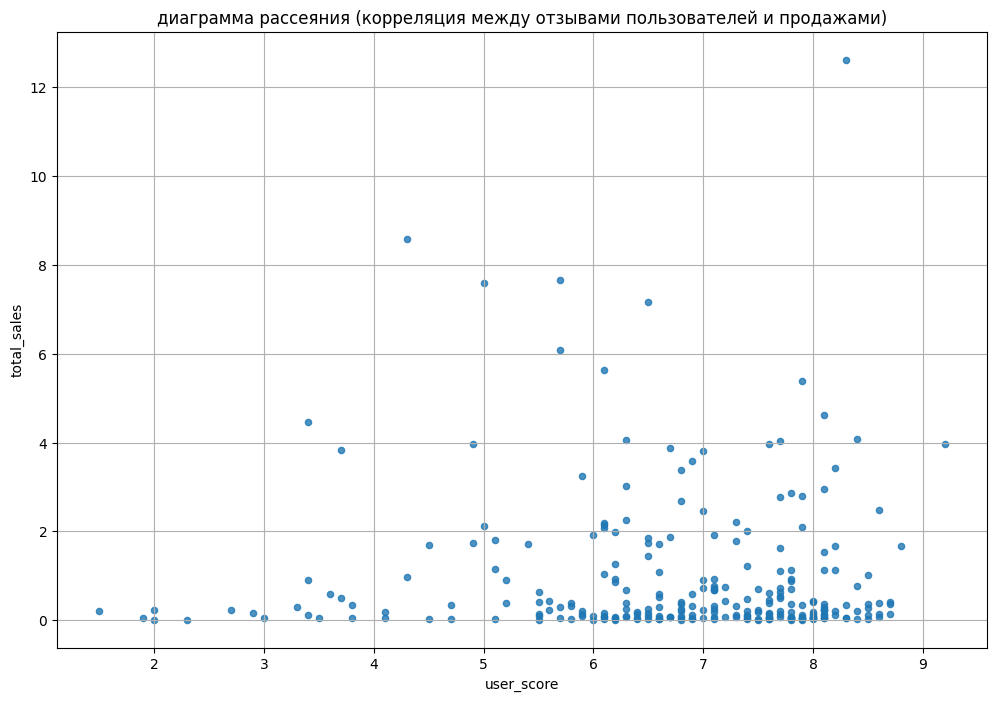

In [49]:
df_9.plot(
    x='user_score',    
    y='total_sales', 
    kind='scatter', 
    alpha=0.8, 
   # xlim=(0, 100),
 #   ylim=(0, 6),
    figsize=(12, 8),
    grid=True,
    title='диаграмма рассеяния (корреляция между отзывами пользователей и продажами)'
)

Корреляция всё же есть. Почистим немного выборку и выберем игры только с положительной оценкой больше 7 балов.

In [50]:
df_9.query("user_score >= 7")[['user_score', 'total_sales']].corr()

,user_score,total_sales
user_score,1.000000,0.105122
total_sales,0.105122,1.000000


В итоге, видим положительную корреляцию, но уже не 2 процента, как вначале было подсчитано, а больше 10 %.
Значит отзывы пользователей всё же влияют на продажи, но только положительные.

<Axes: title={'center': 'диаграмма рассеяния (корреляция между отзывами пользователей и продажами)'}, xlabel='user_score', ylabel='total_sales'>

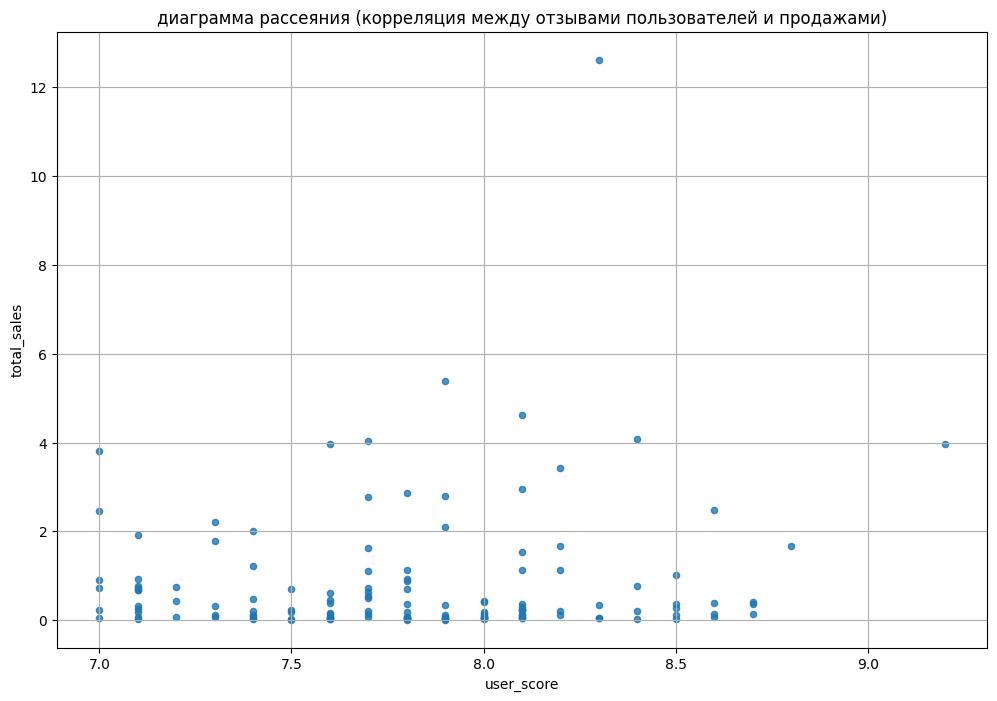

In [51]:
df_9.query("user_score >= 7")[['user_score', 'total_sales']].plot(
    x='user_score',    
    y='total_sales', 
    kind='scatter', 
    alpha=0.8, 
   # xlim=(0, 100),
 #   ylim=(0, 6),
    figsize=(12, 8),
    grid=True,
    title='диаграмма рассеяния (корреляция между отзывами пользователей и продажами)'
)

### Соотнесите выводы с продажами игр на других платформах.

Нас интересуют следующие платформы: 3DS, PSV, WiiU, XOne, PS4, PC. 

Думаю, что выводы сделанные выше по PS4 можно применить также и к платформам: 3DS, PSV, WiiU, XOne, PC. 

In [52]:
df.query("platform == '3DS'")[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.000000,0.744168,0.349401
user_score,0.744168,1.000000,0.224808
total_sales,0.349401,0.224808,1.000000


In [53]:
df.query("platform == 'PSV'")[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.000000,0.733471,0.131517
user_score,0.733471,1.000000,0.013580
total_sales,0.131517,0.013580,1.000000


In [54]:
df.query("platform == 'WiiU'")[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.00000,0.770080,0.348380
user_score,0.77008,1.000000,0.400219
total_sales,0.34838,0.400219,1.000000


In [55]:
df.query("platform == 'XOne'")[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.000000,0.472462,0.416998
user_score,0.472462,1.000000,-0.068925
total_sales,0.416998,-0.068925,1.000000


In [56]:
df.query("platform == 'PC'")[['critic_score', 'user_score', 'total_sales']].corr()

,critic_score,user_score,total_sales
critic_score,1.000000,0.557752,0.256887
user_score,0.557752,1.000000,0.010476
total_sales,0.256887,0.010476,1.000000


проверил, выводы сделанные выше по PS4 можно применить не ко всем платформам, а только к:  PSV, XOne, PC.

по этим платформам : WiiU, 3DS - отзывы пользователей почти также влияют на продажи как и отзывы критиков, а по платформе WiiU - отзывы пользователей сильнее влияют на объёмы продаж, чем отзывы критиков. 

### Посмотрите на общее распределение игр по жанрам. Что можно сказать о самых прибыльных жанрах? Выделяются ли жанры с высокими и низкими продажами?

In [57]:
df_4.groupby('genre')['total_sales'].sum().sort_values()

genre
Puzzle            2.21
Strategy          3.96
Simulation       13.13
Adventure        17.55
Platform         18.09
Racing           27.52
Fighting         28.22
Misc             37.55
Role-Playing    101.44
Sports          109.48
Shooter         170.94
Action          199.36
Name: total_sales, dtype: float64

по суммарным объёмам продаж чётко выделяются три категории: 
1. Puzzle            2.21,
   Strategy          3.96
2. Simulation       13.13,
   Adventure        17.55,
   Platform         18.09,
   Racing           27.52,
   Fighting         28.22,
   Misc             37.55
3. Role-Playing    101.70,
   Sports          109.48,
   Shooter         170.94,
   Action          199.36

Самые прибыльные жанры - это из 3-й категории: 
- Role-Playing 101.70,
- Sports 109.48, 
- Shooter 170.94, 
- Action 199.36

Выделяются ли жанры с высокими и низкими продажами? - Да, выделяются.

In [58]:
df_4.groupby('genre').agg({'total_sales': ['count', 'sum', 'median']})

total_sales               
                   count     sum median
genre                                  
Action               619  199.36  0.090
Adventure            185   17.55  0.030
Fighting              60   28.22  0.125
Misc                 113   37.55  0.090
Platform              38   18.09  0.140
Puzzle                14    2.21  0.045
Racing                69   27.52  0.090
Role-Playing         221  101.44  0.110
Shooter              128  170.94  0.515
Simulation            44   13.13  0.100
Sports               161  109.48  0.180
Strategy              37    3.96  0.060

In [59]:
df_4.groupby('genre')['total_sales'].median().reset_index().sort_values(by='total_sales', ascending=False)

,genre,total_sales
8,Shooter,0.515
10,Sports,0.180
4,Platform,0.140
2,Fighting,0.125
7,Role-Playing,0.110
9,Simulation,0.100
0,Action,0.090
3,Misc,0.090
6,Racing,0.090
11,Strategy,0.060


жанр - Shooter	, обычно продаётся лучше других.

## Составьте портрет пользователя каждого региона

**Определите для пользователя каждого региона (NA, EU, JP):**
- Самые популярные платформы (топ-5). Опишите различия в долях продаж.
- Самые популярные жанры (топ-5). Поясните разницу.
- Влияет ли рейтинг ESRB на продажи в отдельном регионе?

Помня про условие, возьмём выборку df_4 и с ней будем работать. Так как у на отсутсвуют прямые данные о популярности той или иной платформы в конкретном регионе, определим популярность платформ, жанров по объёму их продаж в заданных регионах.

**ТОП-5 жанров среди пользователей региона NA:**

In [60]:
df_4.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head()

genre
Shooter         79.02
Action          72.53
Sports          46.13
Role-Playing    33.47
Misc            15.05
Name: na_sales, dtype: float64

**ТОП-5 платформ среди пользователей региона NA:**

In [61]:
df_4.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head()

platform
PS4     98.61
XOne    81.27
X360    28.30
3DS     22.64
PS3     22.05
Name: na_sales, dtype: float64

- в Северной Америке -  - лучше всего продаются игры Shooter на платформе PS4.

**ТОП-5 жанров среди пользователей региона EU:**

In [62]:
df_4.groupby('genre')['eu_sales'].sum().sort_values(ascending=False).head()

genre
Action          74.68
Shooter         65.52
Sports          45.73
Role-Playing    28.17
Racing          14.13
Name: eu_sales, dtype: float64

**ТОП-5 платформ среди пользователей региона EU:**

In [63]:
df_4.groupby('platform')['eu_sales'].sum().sort_values(ascending=False).head()

platform
PS4     130.04
XOne     46.25
PS3      25.54
PC       17.97
3DS      16.12
Name: eu_sales, dtype: float64

- в Европе - лучше всего продаются игры Action на платформе PS4.

**ТОП-5 жанров среди пользователей региона JP:**

In [64]:
df_4.groupby('genre')['jp_sales'].sum().sort_values(ascending=False).head()

genre
Role-Playing    31.16
Action          29.58
Fighting         6.37
Misc             5.61
Shooter          4.87
Name: jp_sales, dtype: float64

**ТОП-5 платформ среди пользователей региона JP:**

In [65]:
df_4.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head()

platform
3DS     44.24
PS4     15.02
PSV     14.54
PS3     11.22
WiiU     7.31
Name: jp_sales, dtype: float64

- в Японии - лучше всего продаются игры Role-Playing на платформе 3DS.

Теперь к вопрсу: Влияет ли рейтинг ESRB на продажи в отдельном регионе?
тут вопрос скользкий, и отвечу на него так - выделить особо популярную возрастную группу по объёмам продаж - возможно. 

А влияет ли данный рейтинг на продажи сказать сложно, игру изначально разрабатывают под самые многочисленные возрастные категории, тоесть для тех кто играет. И скорее всего объём продаж за предьидущий период определяет жанр и рейтинг следующих игр)

Поэтому посмотрим на самые игролюбивые возрастные категории разных регионов.

In [66]:
df_4.groupby('rating')['name'].count().sort_values(ascending=False)

rating
undefined    749
T            271
M            265
E            219
E10+         185
Name: name, dtype: int64

так как пропусков в данном столбце почти половина , трудно делать точные выводы, но
**в целом - видим , что пропуски равнораспределены по платформам, поэтому примерные выводы и сравнения можно делать.**

**по региону JP:**

In [67]:
df_4.groupby('rating')['jp_sales'].sum().sort_values(ascending=False)

rating
undefined    56.90
T            14.78
E             8.94
M             8.01
E10+          4.46
Name: jp_sales, dtype: float64

**по региону NA:**

In [69]:
df_4.groupby('rating')['na_sales'].sum().sort_values(ascending=False)

rating
M            96.42
undefined    64.72
E            50.74
T            38.95
E10+         33.23
Name: na_sales, dtype: float64

**по региону EU:**

In [70]:
df_4.groupby('rating')['eu_sales'].sum().sort_values(ascending=False)

rating
M            93.44
undefined    58.95
E            58.06
T            34.07
E10+         26.16
Name: eu_sales, dtype: float64

**В целом - видим , что пропуски равнораспределены по платформам, поэтому примерные выводы и сравнения можно делать.**
по EU и NA - картина схожая. самая большая по объёму продаж категория - для взрослых, на втором - для каждого, на третьем - для подростков, на четвертом - от 10 и старше.

по JP отличается:
1. подростки
2. для каждого
3. для взрослых
4. от 10 и старше

**Вывод в Японии популярны игры среди подростков, в Европе и Северной Америке - среди взролых.**


В Японии большая часть игр продается без рейтинга ESRB. Это может быть связано с тем, что ESRB ориентирован на рынок Америки, поэтому для анализа Азии стоит использовать какой-то локальный возрастной рейтинг


## Проверьте гипотезы

- Средние пользовательские рейтинги платформ Xbox One и PC одинаковые;
- Средние пользовательские рейтинги жанров Action (англ. «действие», экшен-игры) и Sports (англ. «спортивные соревнования») разные.

Задайте самостоятельно пороговое значение alpha.

Поясните:

Как вы сформулировали нулевую и альтернативную гипотезы;

Какой критерий применили для проверки гипотез и почему.

**Вначале просто подсчитаем средние оценки. Сгруппирую по выбранным платформам, подсчитаю размер выборок и средние user рейтинги**

In [72]:
df_4.query("platform in ['XOne', 'PC']").groupby('platform').agg({'user_score': ['count', 'mean', 'median']})

user_score                 
              count      mean median
platform                            
PC              122  6.298361    6.8
XOne            165  6.594545    6.8

видим, что размер выборки разный, но полученные средние рейтинги почти равные, предполагаю, что гипотеза о равенстве средних user оценок платформ XOne и PC подтверждается с большой долей вероятности.

**теперь подсчитаем средние для этой гипотезы - Средние пользовательские рейтинги жанров Action  и Sports разные.**

In [73]:
df_4.query("genre in ['Action', 'Sports']").groupby('genre').agg({'user_score': ['count', 'mean', 'median']})

user_score                 
            count      mean median
genre                             
Action        297  6.760606    7.1
Sports        127  5.225197    5.5

тут выборки отличаются более чем в 2 раза по размеру, поэтому сложно что-то сказать, значения средних - различаются.

**Подсчитаем то же самое с помощью статистических методов.**

- нам нужно сравнить средние значения двух генеральных совокупностей по взятым из них выборкам. **нулевая гипотеза - средние пользовательские рейтинги платформ Xbox One и PC одинаковые. Альтернативная - рейтинги разные. Критический уровень значимости задаём - 5 %.**
  Таким образом, если нулевая гипотеза не будет отвергнута, то средние пользовательские рейтинги платформ Xbox One и PC с посчитанной вероятностью будут одинаковые.

перед тем как считать , необходимо сделать выборки без пропусков.

In [74]:
df_10 = df_4[~df_4['user_score'].isna()]

сравним размер выборок , если выборки не равны, то equal_var=False

согласно "Статистическому анализу данных": 
    
    
***если у вас достаточно большие и равные по размеру выборки и нет оснований думать, что дисперсии генеральных совокупностей разные, просто сравнивайте средние t-тестом, не указывая параметр equal_var: пусть он примет значение True.***

***Но, если по какой-то причине выборки у вас разного размера или есть сомнения, что дисперсии у совокупностей одинаковые, укажите этот параметр как False, и тест посчитает дисперсии выборок по отдельности.***

делаем следующее:

In [75]:
sample_1 = df_10.query("platform == 'XOne'")['user_score']
sample_2 = df_10.query("platform == 'PC'")['user_score']

In [76]:
len(sample_1) == len(sample_2)

False

In [77]:
alpha = .05 # критический уровень статистической значимости
# если p-value окажется меньше него - отвегнем гипотезу

results = st.ttest_ind(
    sample_1, 
    sample_2, equal_var=False) # так как выборки разного размера, то equal_var=False

print('p-значение: ', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу") 

p-значение:  0.11601398086668832
Не получилось отвергнуть нулевую гипотезу


С вероятностью 11 % средние пользовательские рейтинги платформ Xbox One и PC одинаковые.

- нам нужно сравнить средние значения двух генеральных совокупностей по взятым из них выборкам. **выдвинем нулевую гипотезу - Средние пользовательские рейтинги жанров Action  и Sports одинаковые. Альтернативная - рейтинги разные.** Критический уровень значимости задаём - 5 %.
  Таким образом если нулевая гипотеза будет отвергнута, то Средние пользовательские рейтинги жанров Action  и Sports будут разные.

In [78]:
sample_1 = df_10.query("genre == 'Sports'")['user_score']
sample_2 = df_10.query("genre == 'Action'")['user_score']

alpha = .05 # критический уровень статистической значимости
# если p-value окажется меньше него - отвегнем гипотезу

results = st.ttest_ind(
    sample_1, 
    sample_2, equal_var=False)

print('p-значение: ', results.pvalue)

if results.pvalue < alpha:
    print("Отвергаем нулевую гипотезу")
else:
    print("Не получилось отвергнуть нулевую гипотезу") 

p-значение:  1.1825550382644557e-14
Отвергаем нулевую гипотезу


Средние пользовательские рейтинги жанров Action и Sports - разные.

## Напишите общий вывод

- Исторический путь развития платформы в среднем занимает 11 лет.
- За какой характерный срок появляются новые и исчезают старые платформы? 3-4 года примерно, это так называемое время перехода со старой на новую (например с PS3 на PS4).

- Видим, что платформы XOne, PS4 находятся на этапе "роста" и скорее всего не достигли ещё середины своего пути развития.
- Платформы 3DS, PSV, WiiU находятся на этапе "затухания".
- Так как в среднем, как мы подсчитали ранее, цикл жизни платформы 11 лет, то на 2017 год платформы: 3DS, PSV, WiiU, XOne, PS4 будут ещё актуальны. Лидируют по объёмам продаж - XOne, PS4.
- Платформа PC - универсальная и есть почти у каждого, поэтому производство игр под неё и соответственно их продажи будет всегда актуально.

**Соответственно при планировании экономической политики нашего интернет магазина "Стримчик" на 2017 год, следует сделать упор на следующие платформы: 3DS, PSV, WiiU, XOne, PS4, PC.**

- есть прямая положительная связь - между отзывами критиков и продажами, это значит, что чем выше оценки критиков , тем выше продажи. Поэтому к мнению авторитетных критиков стоит прислушиваться при закупке той или иной игры для продажи.

- Отзывы пользователей тоже влияют на продажи, по разным платформам - сильно по разному .


**Для того, чтобы понимать какие жанры (-> игры), на каких платформах,  предлагать пользователям и для какой аудитории, привожу статистический портрет пользователя с каждого региона.**

ТОП-5 жанров среди пользователей региона NA:

- Shooter         79.02
- Action          72.53
- Sports          46.13
- Role-Playing    33.58
- Misc            15.05

ТОП-5 платформ среди пользователей региона NA:

- PS4     98.61
- XOne    81.27
- X360    28.30
- 3DS     22.64
- PS3     22.05


ТОП-5 жанров среди пользователей региона EU:

- Action          74.68
- Shooter         65.52
- Sports          45.73
- Role-Playing    28.22
- Racing          14.13

ТОП-5 платформ среди пользователей региона EU:

- PS4     130.04
- XOne     46.25
- PS3      25.54
- PC       17.97
- 3DS      16.12

ТОП-5 жанров среди пользователей региона JP:

- Role-Playing    31.23
- Action          29.58
- Fighting         6.37
- Misc             5.61
- Shooter          4.87

ТОП-5 платформ среди пользователей региона JP:

- 3DS     44.24
- PS4     15.02
- PSV     14.61
- PS3     11.22
- WiiU     7.31

по EU и NA - картина схожая. самая большая по объёму продаж категория - для взрослых, на втором - для каждого, на третьем - для подростков, на четвертом - от 10 и старше.

по JP отличается: 1.	подростки, 2.	для каждого, 3.	для взрослых, 4.	от 10 и старше

- в Японии популярны игры среди подростков, в Европе и Северной Америке - среди взролых.
но точных выводы сделать сложно, так как примерно 40 % по каждой платформе это проапуски.
Хотя они и равнораспределены.

